Name - Vanshika Chauhan

Course - B Tech CSE (3rd year)

Subject - Computer Vision

CuId - CU240250953

# Lab Sheet 6

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from skimage import data, color, filters, morphology, segmentation, measure
from skimage.data import binary_blobs
from skimage.segmentation import slic
from sklearn.cluster import KMeans
from scipy import ndimage as ndi

plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully.")
print("OpenCV version:", cv2.__version__)

Libraries imported successfully.
OpenCV version: 4.14.0


## 1. Threshold-Based Segmentation

Build a segmentation tool using:
- Global thresholding
- Otsu thresholding
- Adaptive thresholding


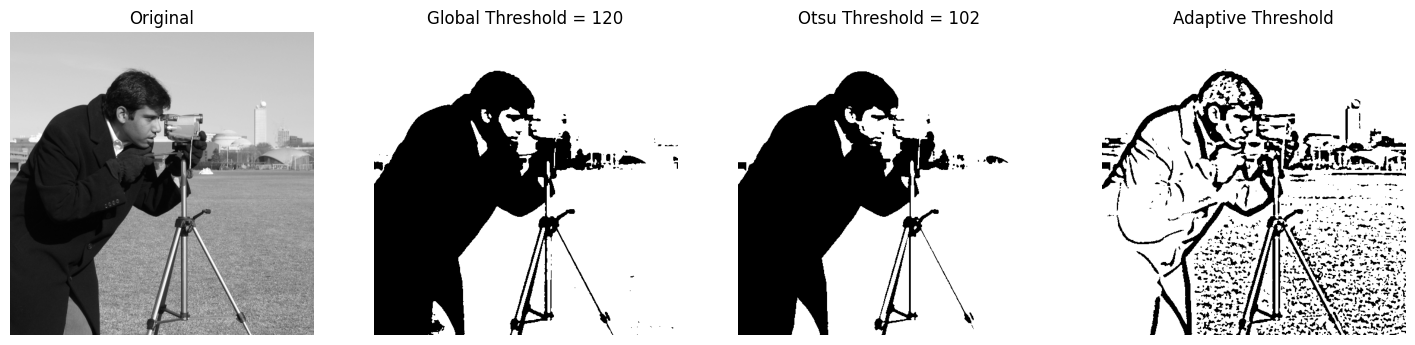

In [ ]:
img = data.camera()
blur = cv2.GaussianBlur(img, (5, 5), 0)

# Adjustable global threshold
global_threshold = 120
_, global_mask = cv2.threshold(blur, global_threshold, 255, cv2.THRESH_BINARY)

# Otsu threshold
otsu_threshold, otsu_mask = cv2.threshold(
    blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Adaptive threshold
adaptive_mask = cv2.adaptiveThreshold(
    blur, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31, 5
)

fig, ax = plt.subplots(1, 4, figsize=(18, 5))
ax[0].imshow(img, cmap="gray")
ax[0].set_title("Original")

ax[1].imshow(global_mask, cmap="gray")
ax[1].set_title(f"Global Threshold = {global_threshold}")

ax[2].imshow(otsu_mask, cmap="gray")
ax[2].set_title(f"Otsu Threshold = {otsu_threshold:.0f}")

ax[3].imshow(adaptive_mask, cmap="gray")
ax[3].set_title("Adaptive Threshold")

for a in ax:
    a.axis("off")

plt.show()


## 2. Region-Growing Segmentation

Starting from a selected seed point, neighboring pixels are added when their intensity is sufficiently similar to the region's current mean.

The seed coordinates can be changed in the code.


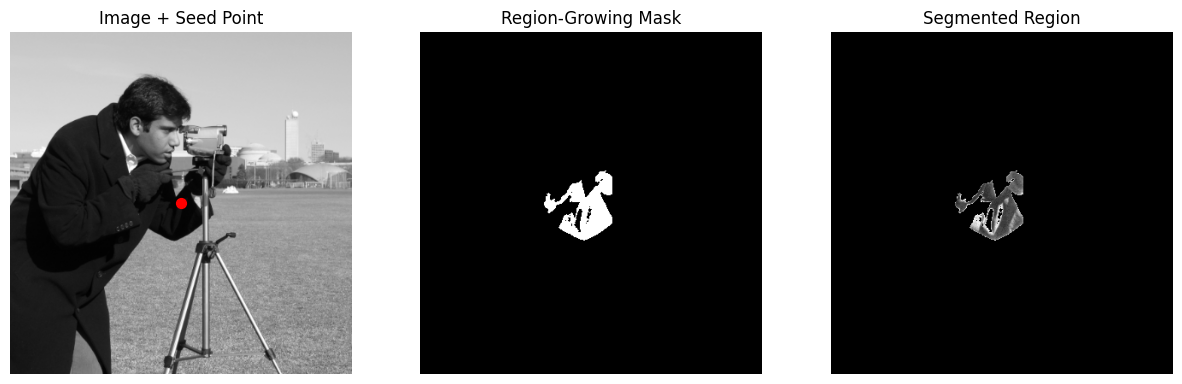

In [ ]:
img = data.camera()
img_small = cv2.resize(img, (400, 400))
def region_growing(gray, seed, tolerance=12):
    h, w = gray.shape
    visited = np.zeros((h, w), dtype=bool)
    region = np.zeros((h, w), dtype=np.uint8)

    queue = [seed]
    visited[seed[0], seed[1]] = True
    region_mean = float(gray[seed])

    neighbors = [
        (-1, -1), (-1, 0), (-1, 1),
        (0, -1),           (0, 1),
        (1, -1),  (1, 0),  (1, 1)
    ]
    count = 0
    while queue:
        r, c = queue.pop(0)

        if abs(float(gray[r, c]) - region_mean) <= tolerance:
            region[r, c] = 255
            count += 1
            region_mean = (
                region_mean * (count - 1) + float(gray[r, c])
            ) / count

            for dr, dc in neighbors:
                nr, nc = r + dr, c + dc
                if 0 <= nr < h and 0 <= nc < w and not visited[nr, nc]:
                    visited[nr, nc] = True
                    if abs(float(gray[nr, nc]) - region_mean) <= tolerance:
                        queue.append((nr, nc))

    return region

# Change these coordinates to select another seed
seed = (200, 200)
mask = region_growing(img_small, seed, tolerance=12)

result = cv2.bitwise_and(img_small, img_small, mask=mask)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img_small, cmap="gray")
ax[0].scatter(seed[1], seed[0], c="red", s=50)
ax[0].set_title("Image + Seed Point")

ax[1].imshow(mask, cmap="gray")
ax[1].set_title("Region-Growing Mask")

ax[2].imshow(result, cmap="gray")
ax[2].set_title("Segmented Region")

for a in ax:
    a.axis("off")
plt.show()


## 3. Split-and-Merge Segmentation

The image is recursively split into four regions when the region variance is high. Similar neighboring regions are then merged using a simple mean-intensity criterion.


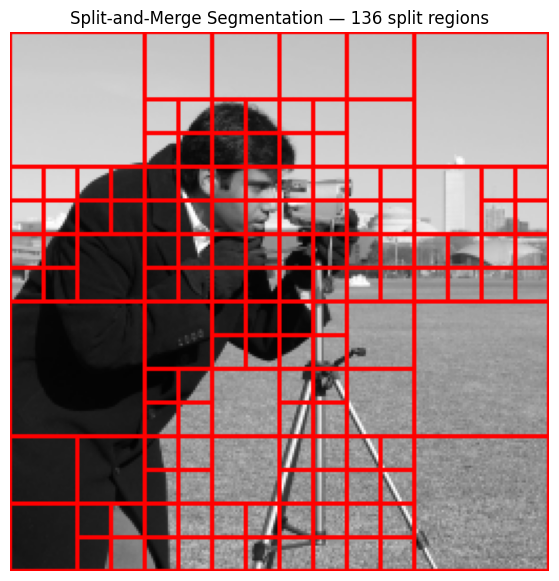

Initial split regions: 136
Merged groups: 57


In [ ]:
img = data.camera()
img = cv2.resize(img, (256, 256)).astype(np.float32)

# Use a power-of-two image for recursive splitting
min_size = 16
variance_threshold = 450

regions = []

def split_region(x, y, size):
    block = img[y:y+size, x:x+size]
    if size <= min_size or np.var(block) <= variance_threshold:
        regions.append((x, y, size, float(np.mean(block))))
        return

    half = size // 2
    split_region(x, y, half)
    split_region(x + half, y, half)
    split_region(x, y + half, half)
    split_region(x + half, y + half, half)

split_region(0, 0, 256)
# Merge neighboring regions with similar mean intensity
merged = []
used = [False] * len(regions)
merge_threshold = 18
for i, r1 in enumerate(regions):
    if used[i]:
        continue
    x, y, s, mean1 = r1
    group = [r1]
    used[i] = True
    changed = True
    while changed:
        changed = False
        current_mean = np.mean([g[3] for g in group])

        for j, r2 in enumerate(regions):
            if used[j]:
                continue

            x2, y2, s2, mean2 = r2

            # Check whether rectangles touch/overlap
            horizontal_touch = (
                abs((x+s) - x2) <= 1 or abs((x2+s2) - x) <= 1
            ) and not (y+s < y2 or y2+s2 < y)

            vertical_touch = (
                abs((y+s) - y2) <= 1 or abs((y2+s2) - y) <= 1
            ) and not (x+s < x2 or x2+s2 < x)

            if (horizontal_touch or vertical_touch) and abs(mean2 - current_mean) < merge_threshold:
                group.append(r2)
                used[j] = True
                changed = True
    merged.append(group)

# Visualize final region boundaries
output = cv2.cvtColor(img.astype(np.uint8), cv2.COLOR_GRAY2RGB)

for group in merged:
    for x, y, s, mean_value in group:
        cv2.rectangle(output, (x, y), (x+s-1, y+s-1), (255, 0, 0), 1)

plt.figure(figsize=(10, 7))
plt.imshow(output)
plt.axis("off")
plt.title(f"Split-and-Merge Segmentation — {len(regions)} split regions")
plt.show()

print("Initial split regions:", len(regions))
print("Merged groups:", len(merged))

Vanshika Chauhan

CU240250953

## 4. Watershed Segmentation

Watershed is useful for separating touching objects. Coins are used as a sample object image.


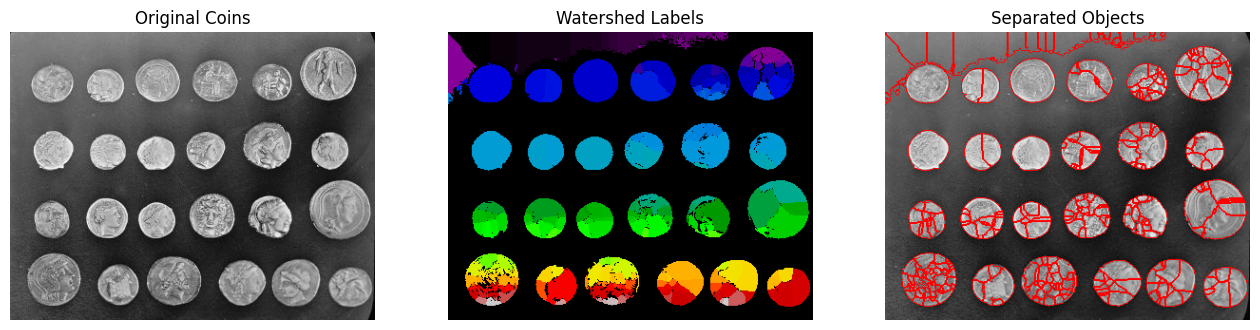

Number of segmented objects: 324


In [ ]:
img = data.coins()

# Binary foreground
binary = img > filters.threshold_otsu(img)
# Remove small noise
binary = morphology.remove_small_objects(binary, min_size=80)
# Distance transform
distance = ndi.distance_transform_edt(binary)
# Find local maxima as markers
local_max = morphology.local_maxima(distance)
markers, _ = ndi.label(local_max)
# Watershed
labels = segmentation.watershed(-distance, markers, mask=binary)
# Boundaries
boundary = segmentation.mark_boundaries(
    color.gray2rgb(img), labels, color=(1, 0, 0)
)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(img, cmap="gray")
ax[0].set_title("Original Coins")
ax[1].imshow(labels, cmap="nipy_spectral")
ax[1].set_title("Watershed Labels")
ax[2].imshow(boundary)
ax[2].set_title("Separated Objects")
for a in ax:
    a.axis("off")
plt.show()

print("Number of segmented objects:", labels.max())

## 5. K-Means Colour Segmentation

Cluster image pixels into a selected number of colour groups. Change `K` to control the number of segments.


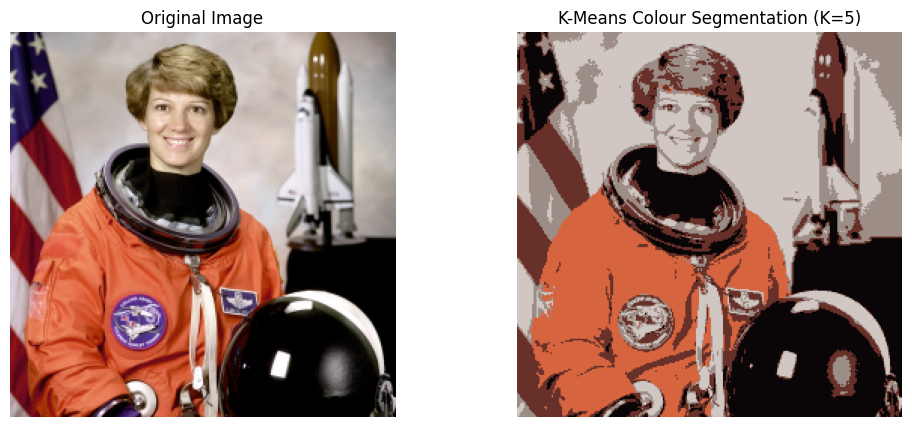

Cluster centres:
[[156 141 135]
 [ 10   5   6]
 [214 100  63]
 [103  48  41]
 [208 198 194]]


In [ ]:
img = data.astronaut()
small = cv2.resize(img, (256, 256))

K = 5

pixels = small.reshape((-1, 3)).astype(np.float32)
kmeans = KMeans(
    n_clusters=K,
    random_state=42,
    n_init=10
)
labels = kmeans.fit_predict(pixels)
centers = np.uint8(kmeans.cluster_centers_)
segmented_pixels = centers[labels]
segmented = segmented_pixels.reshape(small.shape)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(small)
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(segmented)
ax[1].set_title(f"K-Means Colour Segmentation (K={K})")
ax[1].axis("off")

plt.show()
print("Cluster centres:")
print(centers)

## 6. Foreground Extraction using GrabCut

GrabCut uses foreground/background models and graph-cut optimization. A rectangle is supplied around the foreground object.


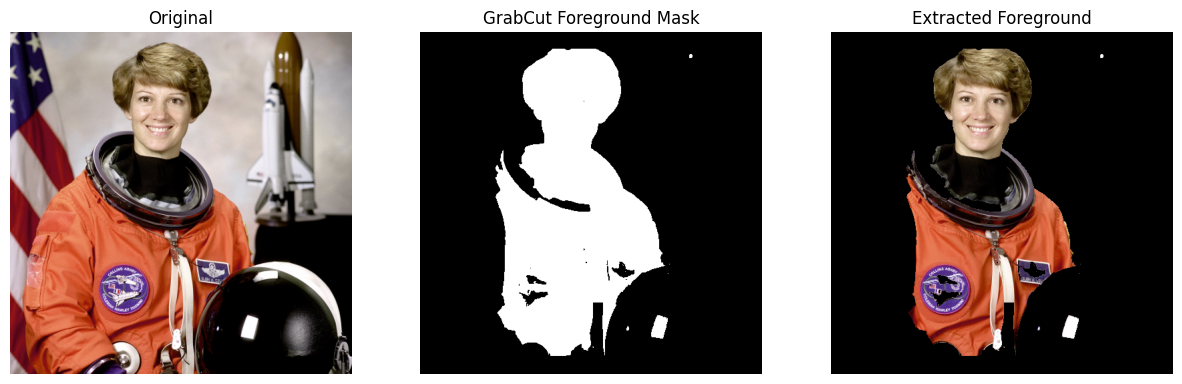

In [ ]:
# Experiment 6 — GrabCut foreground extraction
img = data.astronaut()
img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
mask = np.zeros(img_bgr.shape[:2], np.uint8)
# Rectangle approximately containing the foreground person
h, w = img_bgr.shape[:2]
rect = (int(0.15*w), int(0.05*h), int(0.70*w), int(0.90*h))

bgd_model = np.zeros((1, 65), np.float64)
fgd_model = np.zeros((1, 65), np.float64)
cv2.grabCut(
    img_bgr, mask, rect,
    bgd_model, fgd_model,
    5,
    cv2.GC_INIT_WITH_RECT
)
# Foreground = probable foreground or definite foreground
foreground_mask = np.where(
    (mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD),
    1, 0
).astype("uint8")

result = img * foreground_mask[:, :, np.newaxis]
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img)
ax[0].set_title("Original")
ax[0].axis("off")

ax[1].imshow(foreground_mask, cmap="gray")
ax[1].set_title("GrabCut Foreground Mask")
ax[1].axis("off")

ax[2].imshow(result)
ax[2].set_title("Extracted Foreground")
ax[2].axis("off")

plt.show()

## 7. Normalized-Cut Based Segmentation

A practical normalized-cut style demonstration is implemented using a graph of image superpixels. The superpixels are connected according to spatial/color similarity and partitioned using a spectral clustering approach.


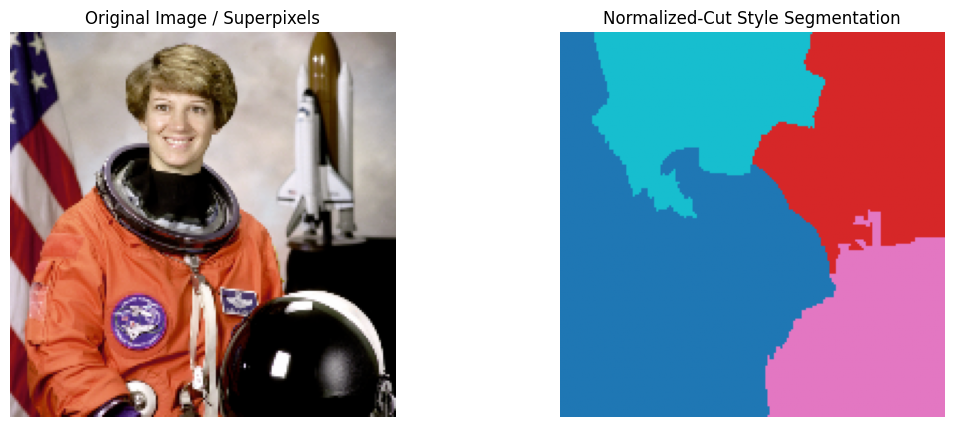

Superpixels: 47
Final regions: 4


In [ ]:
from sklearn.cluster import SpectralClustering
img = cv2.resize(data.astronaut(), (180, 180))
# Create superpixels to reduce graph size
segments = slic(
    img,
    n_segments=80,
    compactness=10,
    start_label=0
)
num_segments = segments.max() + 1
# Calculate mean RGB value for every superpixel
features = np.zeros((num_segments, 3), dtype=np.float32)
for i in range(num_segments):
    features[i] = img[segments == i].mean(axis=0)

# Build a spatial/color affinity matrix
affinity = np.zeros((num_segments, num_segments), dtype=np.float32)

# Centroids
centroids = np.zeros((num_segments, 2))
for i in range(num_segments):
    ys, xs = np.where(segments == i)
    centroids[i] = [ys.mean(), xs.mean()]

for i in range(num_segments):
    for j in range(i + 1, num_segments):
        spatial_dist = np.linalg.norm(centroids[i] - centroids[j])
        color_dist = np.linalg.norm(features[i] - features[j])

        # Only connect reasonably close superpixels
        if spatial_dist < 45:
            weight = np.exp(
                -(color_dist**2)/(2*35**2)
                -(spatial_dist**2)/(2*30**2)
            )
            affinity[i, j] = weight
            affinity[j, i] = weight

# Spectral clustering approximates a normalized-cut partition
n_clusters = 4
spectral = SpectralClustering(
    n_clusters=n_clusters,
    affinity="precomputed",
    assign_labels="kmeans",
    random_state=42
)

cluster_labels = spectral.fit_predict(affinity + np.eye(num_segments) * 1e-6)
segmented = cluster_labels[segments]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].imshow(img)
ax[0].set_title("Original Image / Superpixels")
ax[0].axis("off")
ax[1].imshow(segmented, cmap="tab10")
ax[1].set_title("Normalized-Cut Style Segmentation")
ax[1].axis("off")

plt.show()

print("Superpixels:", num_segments)
print("Final regions:", n_clusters)

# 8. Medical Image Segmentation
A Shepp-Logan phantom is used as a sample medical image. Thresholding and morphological operations isolate a region and its outline.




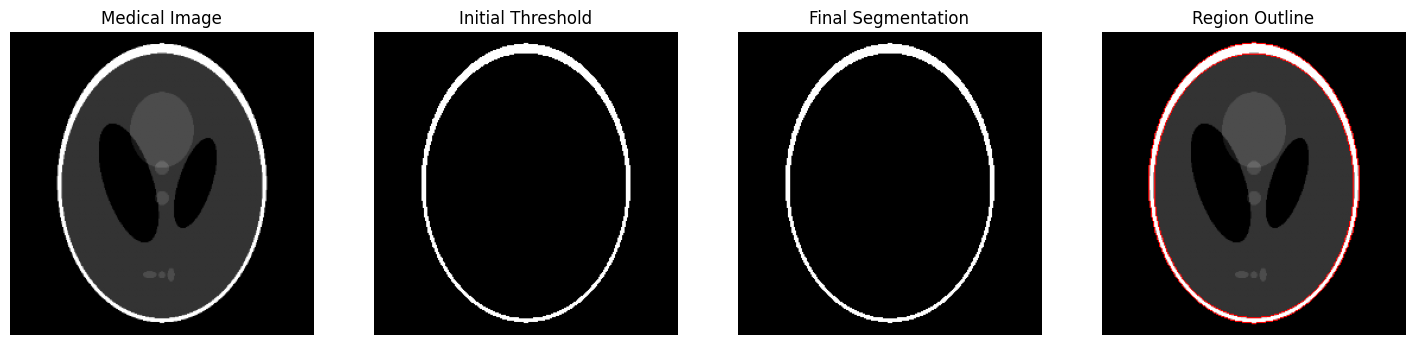

Medical image segmentation completed.
Detected regions: 1


In [ ]:
phantom = shepp_logan_phantom()
phantom = cv2.resize(phantom, (256, 256))

threshold = 0.55
initial_mask = phantom > threshold

clean_mask = morphology.remove_small_objects(initial_mask, min_size=80)
clean_mask = morphology.binary_closing(clean_mask, morphology.disk(2))

labels = measure.label(clean_mask)
final_mask = np.zeros_like(clean_mask, dtype=bool)

for region in measure.regionprops(labels):
    if region.area > 100:
        final_mask[labels == region.label] = True

outline = segmentation.find_boundaries(final_mask, mode="outer")

overlay = np.dstack([phantom, phantom, phantom])
overlay[outline] = [1, 0, 0]

fig, ax = plt.subplots(1, 4, figsize=(18, 5))
ax[0].imshow(phantom, cmap="gray"); ax[0].set_title("Medical Image"); ax[0].axis("off")
ax[1].imshow(initial_mask, cmap="gray"); ax[1].set_title("Initial Threshold"); ax[1].axis("off")
ax[2].imshow(final_mask, cmap="gray"); ax[2].set_title("Final Segmentation"); ax[2].axis("off")
ax[3].imshow(overlay); ax[3].set_title("Region Outline"); ax[3].axis("off")
plt.show()

print("Medical image segmentation completed.")
print("Detected regions:", len(measure.regionprops(measure.label(final_mask))))



# 9. License-Plate / Text-Region Segmentation

Detected text regions: 1


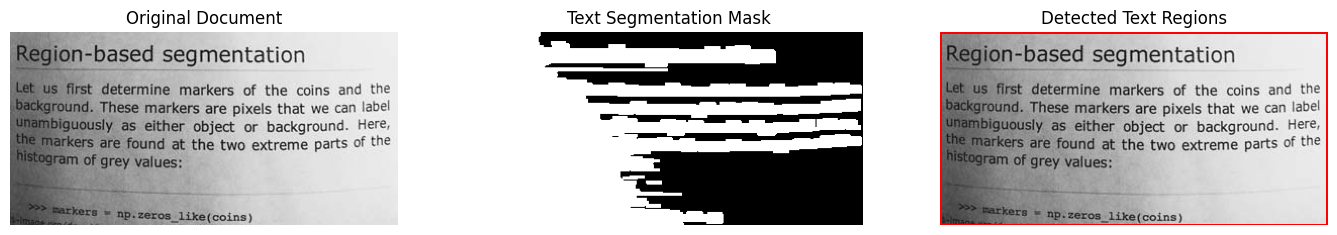

In [ ]:
text_img = data.page()
gray = text_img if text_img.ndim == 2 else cv2.cvtColor(text_img, cv2.COLOR_RGB2GRAY)

binary = cv2.threshold(
    gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)[1]

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 3))
text_regions = cv2.dilate(binary, kernel, iterations=1)

contours, _ = cv2.findContours(
    text_regions, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

output = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
boxes = []

for contour in contours:
    x, y, w, h = cv2.boundingRect(contour)
    if w > 20 and h > 5:
        boxes.append((x, y, w, h))
        cv2.rectangle(output, (x, y), (x+w, y+h), (255, 0, 0), 2)

print("Detected text regions:", len(boxes))

fig, ax = plt.subplots(1, 3, figsize=(17, 6))
ax[0].imshow(gray, cmap="gray"); ax[0].set_title("Original Document"); ax[0].axis("off")
ax[1].imshow(text_regions, cmap="gray"); ax[1].set_title("Text Segmentation Mask"); ax[1].axis("off")
ax[2].imshow(output); ax[2].set_title("Detected Text Regions"); ax[2].axis("off")
plt.show()

10. Segmentation Evaluation Dashboard
Compare segmentation methods against a known ground-truth mask using IoU and Dice Score.
Methods:
 -- Global threshold
 -- Otsu threshold
 -- K-Means segmentation

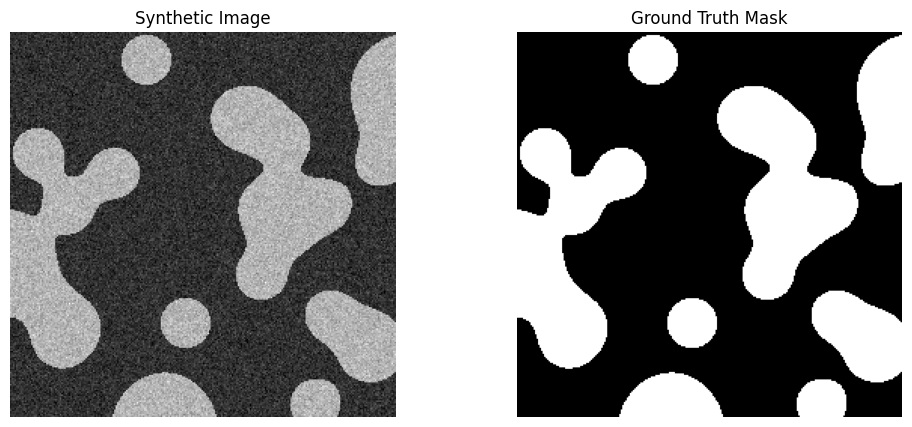

In [ ]:
# Question 10 — Create image and known ground truth
from skimage.data import binary_blobs

ground_truth = binary_blobs(
    length=256,
    blob_size_fraction=0.20,
    n_dim=2,
    volume_fraction=0.35
)

rng = np.random.default_rng(42)

synthetic = np.where(
    ground_truth,
    180 + rng.normal(0, 18, ground_truth.shape),
    50 + rng.normal(0, 18, ground_truth.shape)
)

synthetic = np.clip(synthetic, 0, 255).astype(np.uint8)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(synthetic, cmap="gray")
ax[0].set_title("Synthetic Image")
ax[0].axis("off")

ax[1].imshow(ground_truth, cmap="gray")
ax[1].set_title("Ground Truth Mask")
ax[1].axis("off")

plt.show()


In [ ]:
# Segmentation methods
global_mask = synthetic > 120

otsu_value = filters.threshold_otsu(synthetic)
otsu_mask = synthetic > otsu_value

pixels = synthetic.reshape(-1, 1).astype(np.float32)
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
labels = kmeans.fit_predict(pixels)

centers = kmeans.cluster_centers_.flatten()
bright_cluster = np.argmax(centers)
kmeans_mask = labels.reshape(synthetic.shape) == bright_cluster

print("Otsu threshold:", otsu_value)
print("K-Means cluster centres:", centers)


Otsu threshold: 114
K-Means cluster centres: [ 49.41949 179.80405]


In [ ]:
# IoU and Dice functions
def iou_score(prediction, ground_truth):
    prediction = prediction.astype(bool)
    ground_truth = ground_truth.astype(bool)

    intersection = np.logical_and(prediction, ground_truth).sum()
    union = np.logical_or(prediction, ground_truth).sum()

    return intersection / union if union > 0 else 1.0

def dice_score(prediction, ground_truth):
    prediction = prediction.astype(bool)
    ground_truth = ground_truth.astype(bool)

    intersection = np.logical_and(prediction, ground_truth).sum()
    denominator = prediction.sum() + ground_truth.sum()

    return 2 * intersection / denominator if denominator > 0 else 1.0

methods = {
    "Global Threshold": global_mask,
    "Otsu Threshold": otsu_mask,
    "K-Means": kmeans_mask
}

results = []

for name, mask in methods.items():
    results.append({
        "Method": name,
        "IoU": iou_score(mask, ground_truth),
        "Dice Score": dice_score(mask, ground_truth)
    })

dashboard = pd.DataFrame(results)
display(dashboard)



,Method,IoU,Dice Score
0,Global Threshold,0.999303,0.999651
1,Otsu Threshold,0.999303,0.999651
2,K-Means,0.999303,0.999651


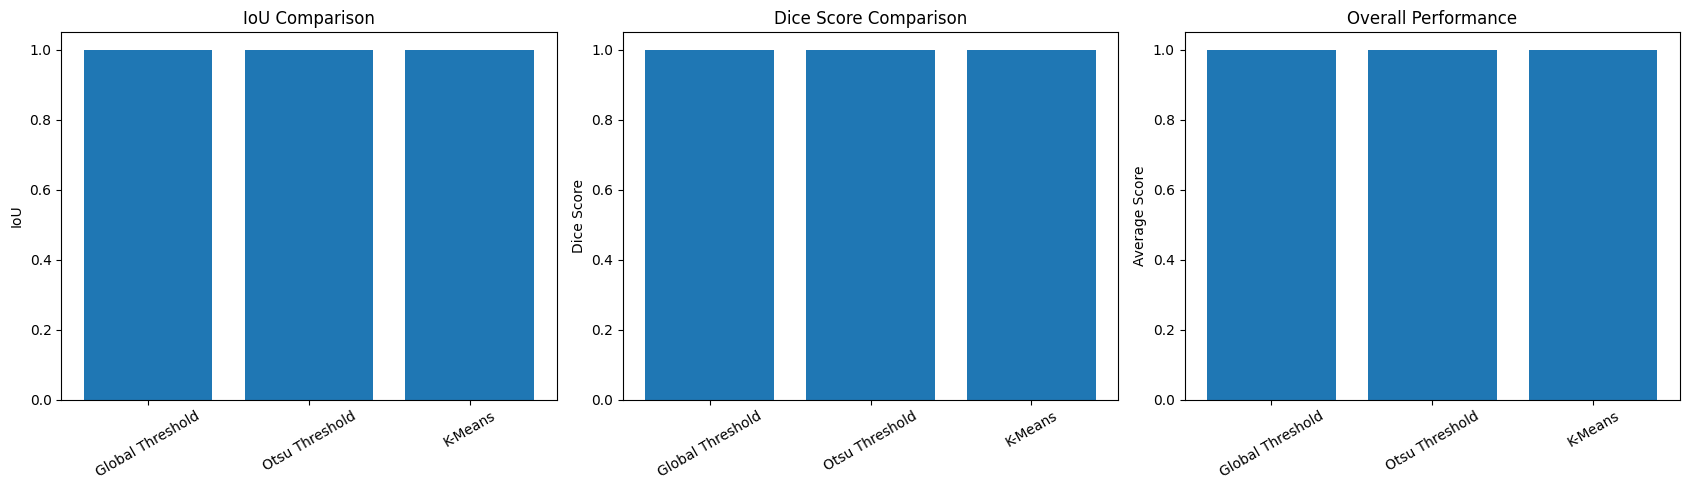

Best method according to Dice Score: Otsu Threshold


In [ ]:
#  Evaluation Dashboard
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].bar(dashboard["Method"], dashboard["IoU"])
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("IoU")
axes[0].set_title("IoU Comparison")
axes[0].tick_params(axis="x", rotation=30)

axes[1].bar(dashboard["Method"], dashboard["Dice Score"])
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("Dice Score")
axes[1].set_title("Dice Score Comparison")
axes[1].tick_params(axis="x", rotation=30)

average = (dashboard["IoU"] + dashboard["Dice Score"]) / 2
axes[2].bar(dashboard["Method"], average)
axes[2].set_ylim(0, 1.05)
axes[2].set_ylabel("Average Score")
axes[2].set_title("Overall Performance")
axes[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

best_method = dashboard.loc[dashboard["Dice Score"].idxmax(), "Method"]
print("Best method according to Dice Score:", best_method)